In [3]:

# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Set visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:

# Load the provided dataset

df = pd.read_excel("instructor_effectiveness_dataset_2000_rows.xlsx")

# Display first five records
df.head()


,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_1861,I_044,C_01,0.300000,14.225955,73.546528,0.647423,0.774572,0.790918,0.108414,3.766211,0.533193
1,B_0354,I_119,C_06,0.657220,22.871110,77.312331,0.425098,0.494936,0.998566,0.280550,5.000000,0.734087
2,B_1334,I_050,C_03,0.300000,16.087517,79.563687,0.700000,0.977901,0.807298,0.207013,3.517386,0.681433
3,B_0906,I_024,C_21,0.639507,24.260687,99.295316,0.334657,0.846515,0.544555,0.306395,4.207578,1.000000
4,B_1290,I_001,C_08,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710


In [6]:

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check statistical summary
print("\nStatistical Summary:")
display(df.describe())


Dataset Shape: (2000, 12)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   str    
 1   instructor_id               2000 non-null   str    
 2   course_id                   2000 non-null   str    
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), str(3)
memory usage: 216.9 KB

Missing

,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.602808,27.035844,77.956126,0.394883,0.776515,0.753188,0.250300,4.207134,0.736519
std,0.159667,5.716641,10.695618,0.162747,0.145231,0.148058,0.100640,0.419209,0.149412
min,0.300000,6.159240,40.386725,0.020000,0.287440,0.251111,0.000000,2.639915,0.259935
25%,0.489260,23.124673,70.897590,0.280035,0.675076,0.652110,0.179845,3.918986,0.633293
50%,0.603091,26.938629,78.020567,0.394820,0.780330,0.756380,0.249771,4.205989,0.737213
75%,0.712797,30.885600,85.444286,0.511432,0.894242,0.856458,0.319204,4.503437,0.845876
max,0.980000,40.000000,100.000000,0.700000,1.000000,1.000000,0.641111,5.000000,1.000000


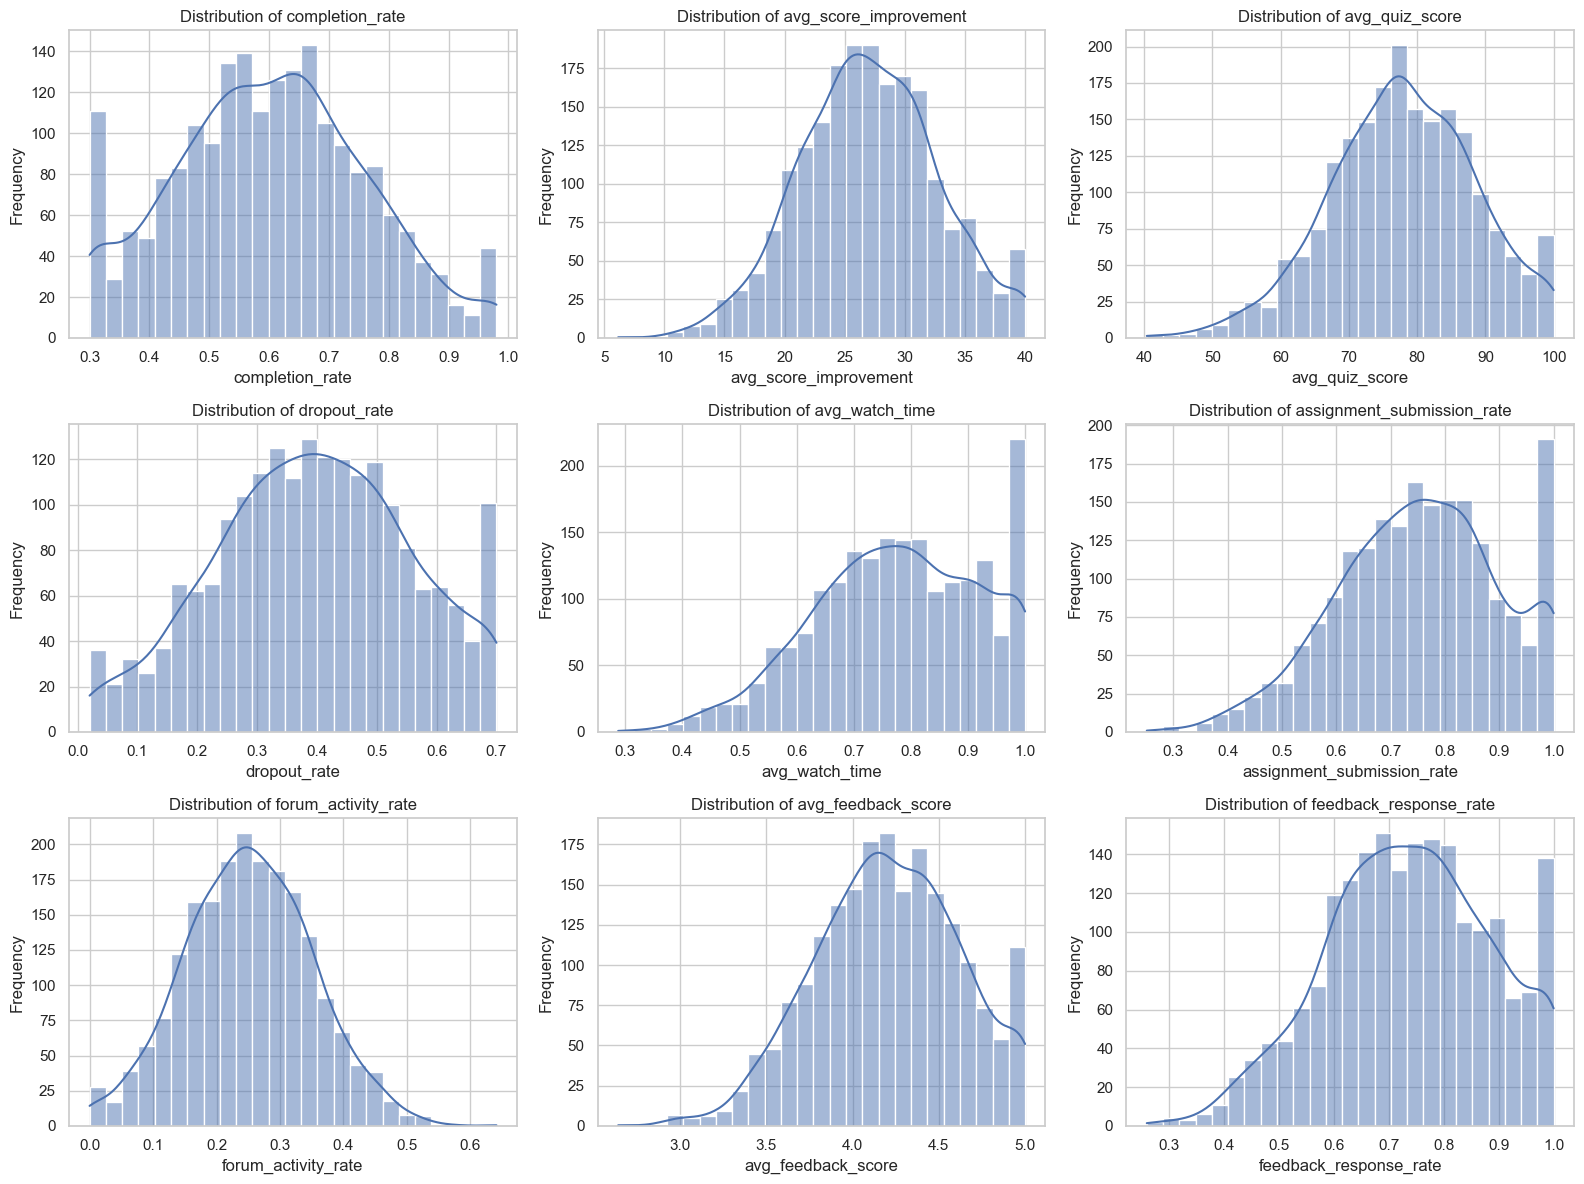

In [7]:

# Select numerical columns for analysis

numeric_columns = df.select_dtypes(include=np.number).columns

# Plot distribution of all numerical features

plt.figure(figsize=(16, 12))

for i, column in enumerate(numeric_columns, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df[column], kde=True, bins=25)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


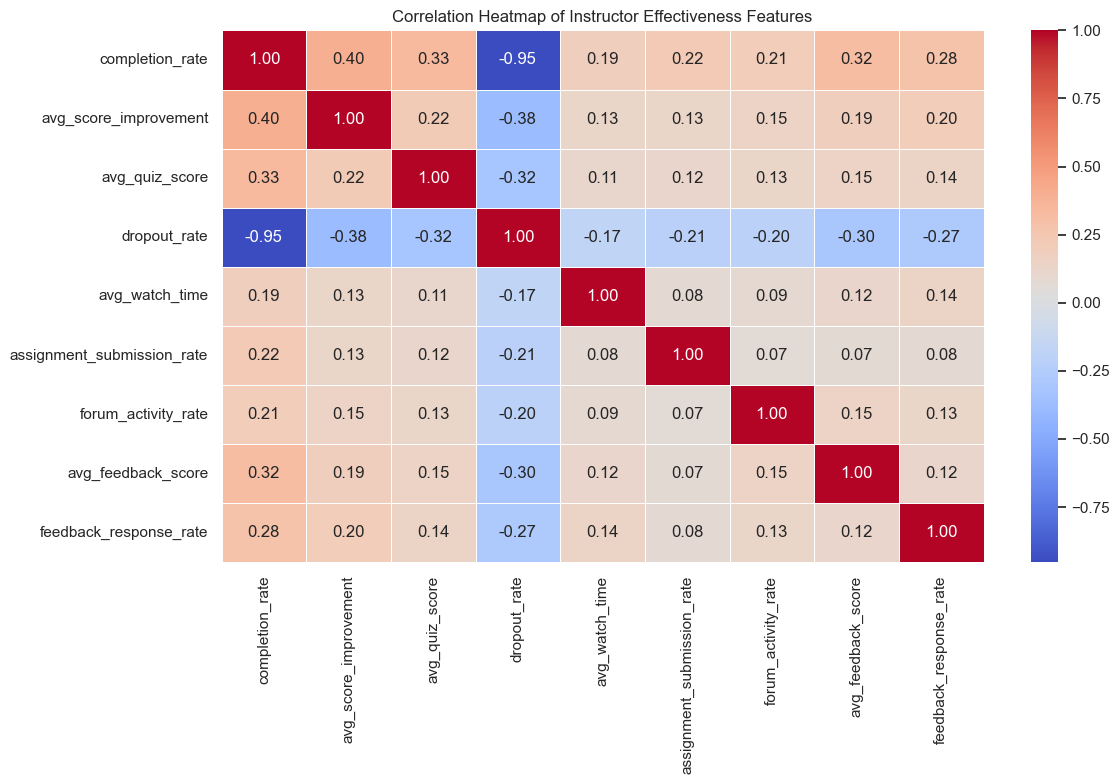

In [8]:

# Calculate correlation between numerical features

correlation_matrix = df[numeric_columns].corr()

# Visualize correlation using heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Instructor Effectiveness Features")
plt.tight_layout()
plt.show()


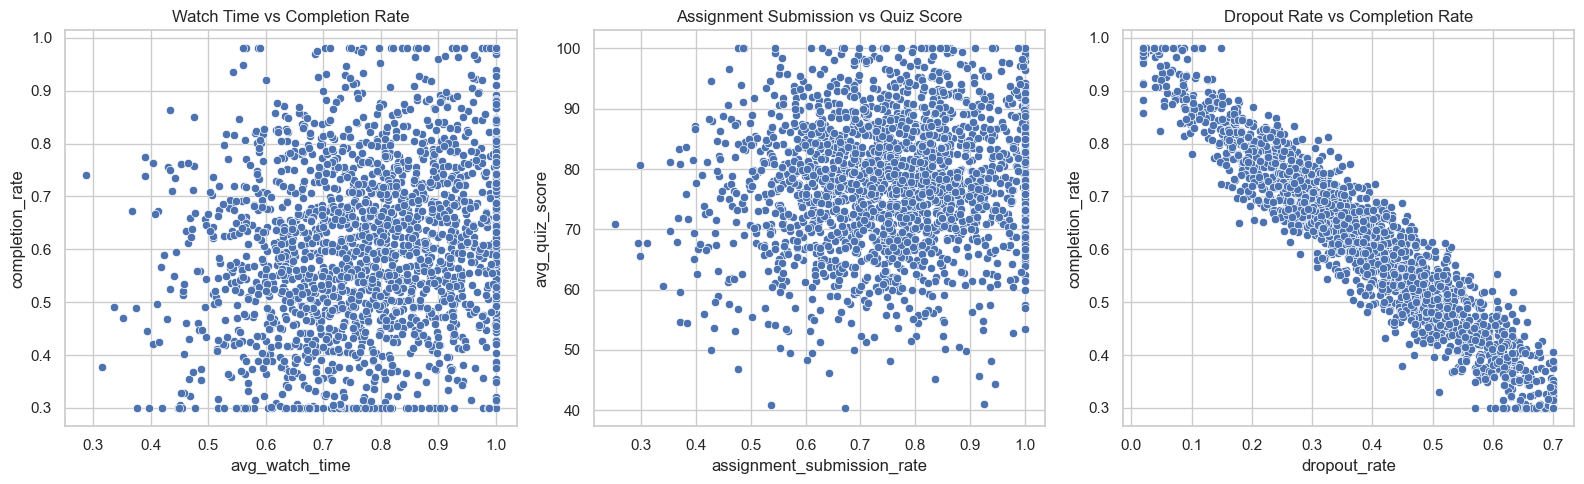

In [9]:

# Relationship between engagement and learner outcomes

plt.figure(figsize=(16, 5))

# 1. Watch time vs Completion rate
plt.subplot(1, 3, 1)
sns.scatterplot(data=df, x='avg_watch_time', y='completion_rate')
plt.title('Watch Time vs Completion Rate')

# 2. Assignment submission vs Quiz score
plt.subplot(1, 3, 2)
sns.scatterplot(data=df, x='assignment_submission_rate', y='avg_quiz_score')
plt.title('Assignment Submission vs Quiz Score')

# 3. Dropout rate vs Completion rate
plt.subplot(1, 3, 3)
sns.scatterplot(data=df, x='dropout_rate', y='completion_rate')
plt.title('Dropout Rate vs Completion Rate')

plt.tight_layout()
plt.show()


In [10]:

# Get correlation values excluding self-correlations

correlation_pairs = (
    correlation_matrix
    .where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(key=abs, ascending=False)
)

print("Top 10 Strongest Correlations:\n")
print(correlation_pairs.head(10))


Top 10 Strongest Correlations:

completion_rate        dropout_rate                 -0.953493
                       avg_score_improvement         0.404161
avg_score_improvement  dropout_rate                 -0.381354
completion_rate        avg_quiz_score                0.333307
                       avg_feedback_score            0.315394
avg_quiz_score         dropout_rate                 -0.315220
dropout_rate           avg_feedback_score           -0.300556
completion_rate        feedback_response_rate        0.279549
dropout_rate           feedback_response_rate       -0.274475
completion_rate        assignment_submission_rate    0.221877
dtype: float64


In [ ]:

### 3.5 Key Observations from Exploratory Data Analysis

1. The dataset contains 2,000 batch-level records and 12 columns.
2. No missing values were identified during data quality checks.
3. The average completion rate is approximately 60.28%.
4. The average dropout rate is approximately 39.49%.
5. The average quiz score is approximately 77.96.
6. The average feedback score is approximately 4.21 out of 5.
7. Forum activity is relatively low, with an average of approximately 25.03%.
8. Distribution plots help identify the spread and concentration of numerical features.
9. Correlation and scatter plots help explore relationships between engagement and learning outcomes.

These observations describe the dataset and do not establish that an instructor directly caused a particular learner outcome.


In [11]:

# Step 4: Create Instructor Effectiveness Score

# Normalize score improvement between 0 and 1
score_improvement_normalized = (
    (df['avg_score_improvement'] - df['avg_score_improvement'].min()) /
    (df['avg_score_improvement'].max() - df['avg_score_improvement'].min())
)

# Normalize quiz score
quiz_score_normalized = df['avg_quiz_score'] / 100

# Normalize feedback score from 1-5 to 0-1
feedback_normalized = (df['avg_feedback_score'] - 1) / 4

# Calculate effectiveness score
df['IES'] = (
    0.20 * df['completion_rate'] +
    0.10 * (1 - df['dropout_rate']) +
    0.10 * score_improvement_normalized +
    0.10 * quiz_score_normalized +
    0.10 * df['avg_watch_time'] +
    0.10 * df['assignment_submission_rate'] +
    0.10 * df['forum_activity_rate'] +
    0.20 * feedback_normalized
)

# Display results
print("Instructor Effectiveness Score calculated successfully!")

display(df[['instructor_id', 'course_id', 'IES']].head(10))

print("\nIES Statistical Summary:")
display(df['IES'].describe())


Instructor Effectiveness Score calculated successfully!


,instructor_id,course_id,IES
0,I_044,C_01,0.498342
1,I_119,C_06,0.693036
2,I_050,C_03,0.523992
3,I_024,C_21,0.677346
4,I_001,C_08,0.701264
5,I_026,C_07,0.604563
6,I_082,C_23,0.678188
7,I_009,C_15,0.659095
8,I_114,C_03,0.712364
9,I_038,C_24,0.422532



IES Statistical Summary:


count    2000.000000
mean        0.659077
std         0.082696
min         0.380970
25%         0.603160
50%         0.659817
75%         0.711347
max         0.902485
Name: IES, dtype: float64

In [12]:

# Step 4.3: Aggregate data at instructor level

instructor_data = df.groupby('instructor_id').agg(
    total_batches=('batch_id', 'count'),
    total_courses=('course_id', 'nunique'),
    avg_completion_rate=('completion_rate', 'mean'),
    avg_dropout_rate=('dropout_rate', 'mean'),
    avg_score_improvement=('avg_score_improvement', 'mean'),
    avg_quiz_score=('avg_quiz_score', 'mean'),
    avg_watch_time=('avg_watch_time', 'mean'),
    avg_assignment_submission=('assignment_submission_rate', 'mean'),
    avg_forum_activity=('forum_activity_rate', 'mean'),
    avg_feedback_score=('avg_feedback_score', 'mean'),
    avg_feedback_response_rate=('feedback_response_rate', 'mean'),
    avg_IES=('IES', 'mean')
).reset_index()

print("Instructor-level aggregation completed!")

print("Instructor Dataset Shape:", instructor_data.shape)

display(instructor_data.head())


Instructor-level aggregation completed!
Instructor Dataset Shape: (120, 13)


,instructor_id,total_batches,total_courses,avg_completion_rate,avg_dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,avg_assignment_submission,avg_forum_activity,avg_feedback_score,avg_feedback_response_rate,avg_IES
0,I_001,25,16,0.543887,0.470593,26.641462,78.900194,0.766513,0.726893,0.240551,4.217743,0.694858,0.635426
1,I_002,20,10,0.730874,0.247194,30.166242,81.737198,0.837393,0.774394,0.289610,4.343002,0.784338,0.731423
2,I_003,18,14,0.768447,0.234828,29.977813,81.590928,0.818441,0.779606,0.296224,4.450034,0.812132,0.744111
3,I_004,17,10,0.458328,0.547261,22.912021,77.680317,0.793130,0.758317,0.226259,4.076410,0.721460,0.595716
4,I_005,19,13,0.859747,0.145733,32.588652,85.828159,0.847026,0.876942,0.333519,4.202516,0.784197,0.787178


Instructor Effectiveness Tier Distribution:
effectiveness_tier
Medium    40
High      40
Low       40
Name: count, dtype: int64


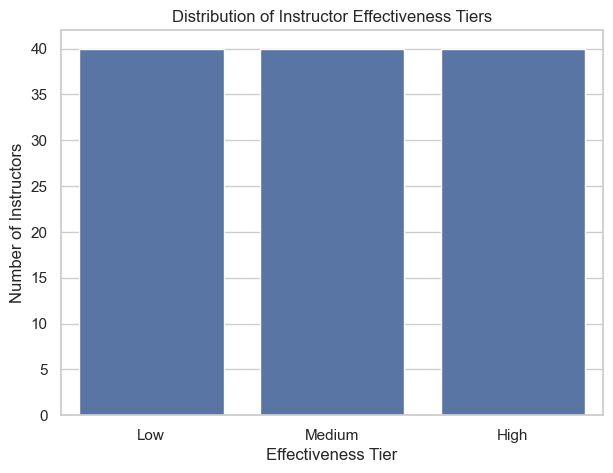

In [13]:

# Step 4.4: Classify instructors into effectiveness tiers

low_threshold = instructor_data['avg_IES'].quantile(0.33)
high_threshold = instructor_data['avg_IES'].quantile(0.67)

def assign_tier(score):
    if score <= low_threshold:
        return 'Low'
    elif score <= high_threshold:
        return 'Medium'
    else:
        return 'High'

instructor_data['effectiveness_tier'] = (
    instructor_data['avg_IES'].apply(assign_tier)
)

# Display tier distribution

print("Instructor Effectiveness Tier Distribution:")

print(instructor_data['effectiveness_tier'].value_counts())

# Visualize tiers

plt.figure(figsize=(7, 5))

sns.countplot(
    data=instructor_data,
    x='effectiveness_tier',
    order=['Low', 'Medium', 'High']
)

plt.title('Distribution of Instructor Effectiveness Tiers')
plt.xlabel('Effectiveness Tier')
plt.ylabel('Number of Instructors')
plt.show()


In [ ]:
## 5. Machine Learning Model

The objective is to predict instructor effectiveness tiers using
aggregated instructor-level performance metrics.

The target variable is effectiveness_tier.

The IES score and instructor identifiers are excluded from model
features to prevent direct target leakage.

In [14]:

# Separate input features and target variable

X = instructor_data.drop(
    columns=['instructor_id', 'avg_IES', 'effectiveness_tier']
)

y = instructor_data['effectiveness_tier']

print("Feature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())


Feature Dataset Shape: (120, 11)
Target Dataset Shape: (120,)

Target Distribution:
effectiveness_tier
Medium    40
High      40
Low       40
Name: count, dtype: int64


In [15]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (96, 11)
Testing Data: (24, 11)


In [16]:

# Import machine learning algorithms

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Initialize models

models = {
    'Dummy Classifier': DummyClassifier(strategy='most_frequent'),

    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight='balanced')
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced'
    )
}

# Train each model

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")


Dummy Classifier trained successfully!
Logistic Regression trained successfully!
Random Forest trained successfully!


In [17]:

# Evaluate all models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, y_pred, average='macro', zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))


,Model,Accuracy,Precision,Recall,F1 Score
0,Dummy Classifier,0.333,0.111,0.333,0.167
1,Logistic Regression,0.875,0.886,0.875,0.874
2,Random Forest,1.000,1.000,1.000,1.000


In [18]:

# Generate predictions

rf_model = models['Random Forest']

y_pred = rf_model.predict(X_test)

# Classification report

print("Random Forest Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=['Low', 'Medium', 'High'],
    zero_division=0
))


Random Forest Classification Report:

              precision    recall  f1-score   support

         Low       1.00      1.00      1.00         8
      Medium       1.00      1.00      1.00         8
        High       1.00      1.00      1.00         8

    accuracy                           1.00        24
   macro avg       1.00      1.00      1.00        24
weighted avg       1.00      1.00      1.00        24



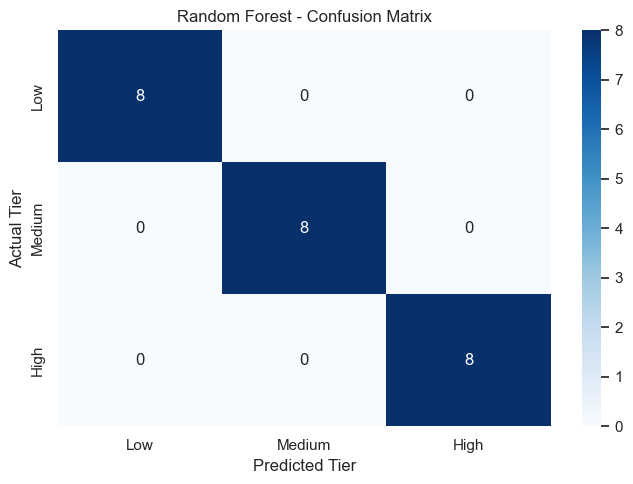

In [19]:

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Low', 'Medium', 'High']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted Tier')
plt.ylabel('Actual Tier')

plt.tight_layout()
plt.show()


,Feature,Importance
2,avg_completion_rate,0.257130
3,avg_dropout_rate,0.249573
4,avg_score_improvement,0.135037
9,avg_feedback_score,0.079334
5,avg_quiz_score,0.065161
10,avg_feedback_response_rate,0.063957
8,avg_forum_activity,0.051688
6,avg_watch_time,0.043732
7,avg_assignment_submission,0.035382
1,total_courses,0.010291


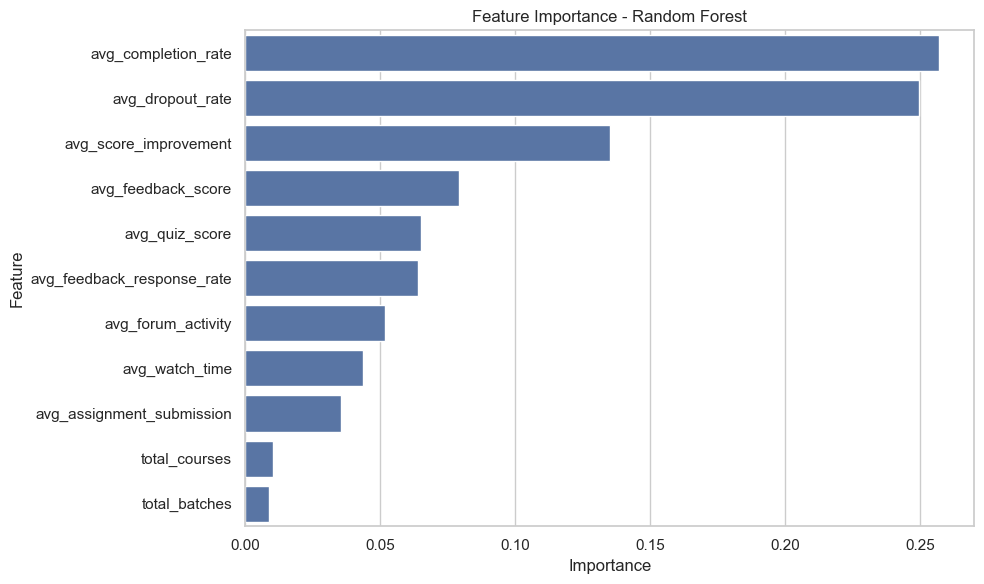

In [20]:

# Extract feature importance

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

# Plot feature importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()


In [ ]:
## 6. Model Interpretation and Results

In [ ]:
### Model Comparison

Three classification models were evaluated:
- Dummy Classifier
- Logistic Regression
- Random Forest

Accuracy, macro precision, macro recall, and macro F1-score
were used to compare their performance.

The Dummy Classifier provides a baseline for comparison.
Logistic Regression provides a simple linear classification approach,
while Random Forest can capture more complex relationships.

The best-performing model should be selected based on its
overall evaluation metrics rather than accuracy alone.

In [ ]:
### Feature Importance Analysis

Feature importance helps identify which input variables were
most useful to the Random Forest model when predicting
instructor effectiveness tiers.

Learning outcome metrics, engagement metrics, and feedback
metrics provide different perspectives on instructor effectiveness.

However, feature importance indicates predictive usefulness,
not direct causation.

The effectiveness tiers are derived from a predefined scoring
formula. Therefore, feature importance partly reflects the
structure of that formula rather than independently discovered
teaching quality.

In [ ]:

## 7. Mandatory Analysis Questions

### Q1. Which features most influenced instructor effectiveness, and why?

Instructor effectiveness was defined using learning outcomes,
learner engagement, and feedback metrics.

Completion rate and average feedback score received the highest
individual weights of 20% each in the effectiveness formula.

Dropout rate, score improvement, quiz score, watch time,
assignment submission, and forum activity received 10% each.

These features were selected because they collectively represent
learner progress, participation, and satisfaction.

The Random Forest feature importance results provide an additional
view of which variables helped predict the assigned effectiveness
tiers. These results should not be interpreted as causal effects.

### Q2. Which variables could be misleading or confounded?

Some variables may be influenced by factors other than instructor
effectiveness.

- Completion rate and dropout rate may depend on course difficulty.
- Quiz scores may depend on learners' previous knowledge.
- Watch time may be affected by video length and learning habits.
- Forum activity may depend on course design and learner preferences.
- Feedback scores may be biased because dissatisfied or satisfied
  learners may be more likely to submit feedback.
- Assignment submission may depend on workload and deadlines.

Therefore, these variables should not be interpreted in isolation.

### Q3. How could this model fail in real-world usage?

The model has several limitations:

1. The dataset contains only 120 unique instructors.
2. Instructor effectiveness tiers are generated using a manually
   defined scoring formula.
3. Aggregating batch data into averages can hide differences
   between individual batches.
4. Course difficulty and learner characteristics are not included.
5. The model may perform poorly on instructors teaching completely
   different courses or working with different learner groups.
6. Changes in course design and teaching methods may affect
   prediction performance over time.

The model predicts the defined effectiveness tiers and does not
establish the actual quality of teaching.

### Q4. What additional data would you want to improve this analysis?

The following additional information could improve the analysis:

- Number of learners enrolled in each batch.
- Learners' pre-course knowledge and assessment scores.
- Course difficulty and course duration.
- Instructor teaching experience.
- Number of live teaching sessions.
- Learner attendance records.
- Detailed assessment performance.
- Historical batch-level performance.
- Feedback response counts and individual response distributions.

These variables could provide a more complete understanding
of learner outcomes and teaching effectiveness.

### Q5. Should this model be used for instructor performance evaluation? Why or why not?

This model should not be used as the sole basis for evaluating
instructor performance.

It can be used as a decision-support tool to identify patterns,
highlight areas for improvement, and help EdTech platforms
understand learner outcomes.

However, the scoring formula contains assumptions, and several
external factors can influence the results.

Human review, additional evidence, transparency, and fairness
should be considered before making any instructor-related
decisions.

The model should support improvement rather than automatically
judge instructors.


In [ ]:

## 8. Conclusion

In this project, an Instructor Effectiveness Modeling system
was developed using batch-level data from an EdTech platform.

The analysis included data cleaning, exploratory data analysis,
correlation analysis, and visualization of learner outcomes,
engagement, and feedback.

An Instructor Effectiveness Score (IES) was defined by combining
eight performance indicators with justified weights.

Batch-level records were aggregated into instructor-level
records, and instructors were classified into Low, Medium,
and High effectiveness tiers using percentile-based thresholds.

Three machine learning approaches were evaluated:
Dummy Classifier, Logistic Regression, and Random Forest.

Model performance was assessed using accuracy, precision,
recall, F1-score, and a confusion matrix.

Feature importance was examined to understand which variables
helped predict the assigned effectiveness tiers.

The analysis demonstrates how learner outcomes, engagement,
and feedback can be combined to study instructor performance.

However, the model has limitations related to dataset size,
feature assumptions, aggregation, and the absence of additional
learner and course information.

Therefore, the model should be considered a decision-support
approach rather than an automated instructor evaluation system.

Future improvements could include learner-level information,
course difficulty, instructor experience, and longitudinal data.
